### Calculating frequency ranges

In [34]:
def frequency_at(level,node_no,nyquist):
    '''
    At specified level, returns the frequency range at a specified node.
    Used to find the frequency range of a node in matlab.

    Parameters
    ----------
    nyquist: float
        the nyquist frequency.
    level: int
        the level of transform to check.
    node_no: int
        the node number of the node, 0 indexed at each level.

    Returns
    -------
    (lo,hi): tuple
        the freqeuncy range of the specified node.
    '''
    for i in (level,node_no):
        if not isinstance(i,int):
            raise ValueError(f'{i} must be an integer')
        
    for i in (level,nyquist):
        if i < 0:
            raise ValueError(f'{i} must be greater than 0')
    
    no_nodes = 2**level
    if node_no > no_nodes:
        raise ValueError(f'level only contains {no_nodes} nodes')

    freq_width = nyquist/no_nodes

    lo = freq_width*node_no
    hi = lo + freq_width
    return (lo,hi)

def node_w_freq(frequency,level,nyquist):
    '''
    Finds node with specified frequency.

    Pararmeters
    -----------
    nyquist: float
        the nyquist frequency.
    level: int
        level of transform to search.
    
    Returns
    -------
    node_no: int
        the node number in matlab which has specified frequency.
    '''
    if not isinstance(level,int):
        raise ValueError('level must be a positive integer')
    
    no_nodes = 2**level
    freq_width = nyquist/no_nodes
    for node_no in range(2**level):
        hi = (node_no+1)*freq_width
        if frequency<hi:
            return node_no

In [36]:
level = 3
nyquist = 50

calc_freq_range = True
if calc_freq_range:
    node_no = 3
    freq_lo,freq_hi = frequency_at(level,node_no,nyquist)
    print(f'frequency range at ({level},{node_no}): ({freq_lo}, {freq_hi})')

find_node = True
if find_node:
    for level in range(1,6):
        freq = 5
        node_no = node_w_freq(freq,level,nyquist)
        print(f'node containing frequency [{freq}]: ({level}, {node_no})')

frequency range at (3,3): (18.75, 25.0)
node containing frequency [5]: (1, 0)
node containing frequency [5]: (2, 0)
node containing frequency [5]: (3, 0)
node containing frequency [5]: (4, 1)
node containing frequency [5]: (5, 3)


### Frequency content of reconstructed subbands

testing 10.0 0.01


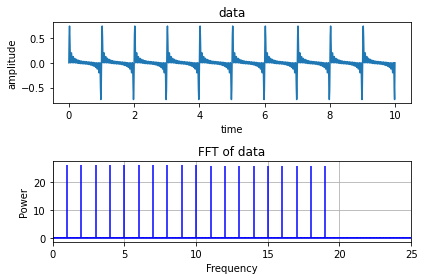

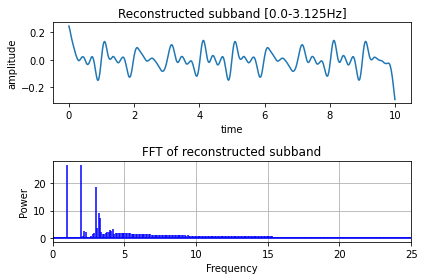

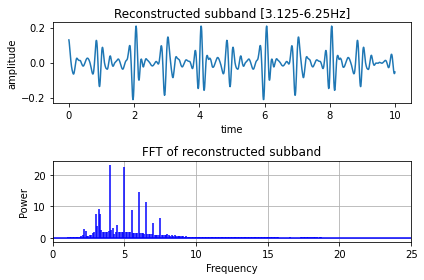

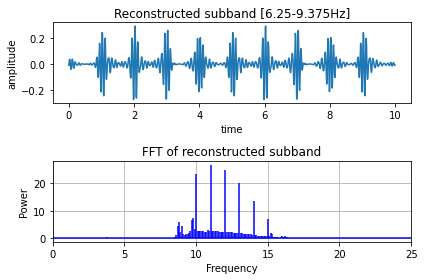

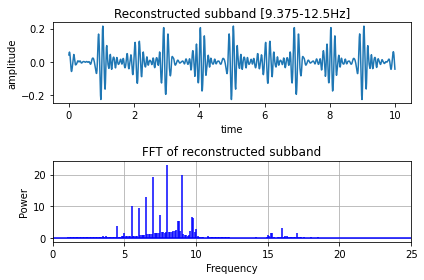

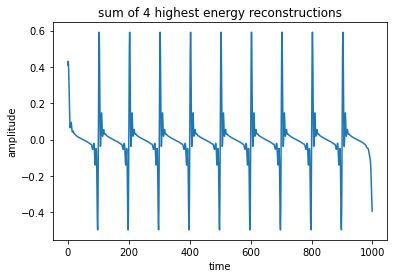

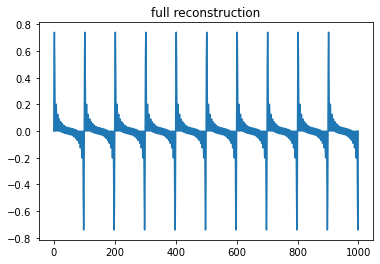

6.112441351533766e-09


In [31]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv

import matplotlib.pyplot as plt
import numpy as np

# keep the same
sampling_rate = 100

# PARAMETERS TO CHANGE
frequencies = list(np.arange(1,20)) # frequency content of wave
duration = 10/min(frequencies) # duration of wave
fft_lim = int(sampling_rate/4) # limit of x-axis in fft plot

wavelet = 'db10'
levels = 4

sort_by_energy = False # plot reconstructions of top 'n_highest' subbands by energy
n_highest = 4 # set sort_by_energy to False to plot subbands in increasing order of frequency



# generate sound wave
data,t_plot = sd.sound_wave(1/len(frequencies),frequencies,duration,sampling_rate)
# data += np.random.normal(0,0.2,len(data))
freq = np.linspace(0,sampling_rate,len(data))
fft = np.fft.fft(data)

# plot sound wave and fft
fig,ax = plt.subplots(2)
ax[0].plot(t_plot,data)
ax[0].set_title('data')
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b")
ax[1].set_title('FFT of data')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Power')
ax[1].set_xlim(0,fft_lim)
ax[1].grid()
fig.tight_layout()
plt.show()

# transform
tr_ob = wpt.dwpt(data,levels,wavelet)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
coeffs = []
rec = []

for node in tr_ob.get_level():
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs.append(tr_ob.nodes2data(rec_nodes))
    inverse = inv.inv_dwpt(coeffs[-1],wavelet)[:len(data)]
    fft = np.fft.fft(inverse)
    rec.append((node,inverse,fft))

# order reconstructed waves
if sort_by_energy:
    rec.sort(key=lambda x:sum(np.array(x[1])**2),reverse=True) # SUPPRESS TO PLOT SUBBANDS IN ORDER

# plot highest energy subbands
x = np.zeros(len(data)) # track sum of highest energy subbands
for i in range(len(rec)):
    node,rec_wave,fft = rec[i] 
    if i in range(n_highest) or node.match_ids(frequencies): # highest energy + freqs of interest
        x+=rec_wave
        fig,ax = plt.subplots(2)
        freq_r = node.frequency_range
        ax[0].plot(t_plot,rec_wave)
        ax[0].set_title(f'Reconstructed subband [{freq_r[0]}-{freq_r[1]}Hz]')
        ax[0].set_xlabel('time')
        ax[0].set_ylabel('amplitude')
        ax[1].stem(freq, np.abs(fft), linefmt='b', markerfmt=" ", basefmt="-b")
        ax[1].set_title(f'FFT of reconstructed subband')
        ax[1].set_xlabel('Frequency')
        ax[1].set_ylabel('Power')
        ax[1].set_xlim(0,fft_lim)
        ax[1].grid()
        fig.tight_layout()
        plt.show()

# plot sum of highest energy subbands
plt.plot(x)
plt.xlabel('time')
plt.ylabel('amplitude')
plt.title(f'sum of {n_highest} highest energy reconstructions')
plt.show()

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()),wavelet)
plt.plot(full_rec[:len(data)])
plt.title('full reconstruction')
plt.show()

print((np.mean(data-x)**2))

### frequency ranges

checking if the frequency ranges are calculated correctly

In [39]:
for node in tr_ob.get_level():
    print(f'{node.path} ({node.level},{node.node_number()}) {node.frequency_range}')

aaaa (4,0) (0.0, 3.125)
aaad (4,1) (3.125, 6.25)
aada (4,2) (6.25, 9.375)
aadd (4,3) (9.375, 12.5)
adaa (4,4) (12.5, 15.625)
adad (4,5) (15.625, 18.75)
adda (4,6) (18.75, 21.875)
addd (4,7) (21.875, 25.0)
daaa (4,8) (25.0, 28.125)
daad (4,9) (28.125, 31.25)
dada (4,10) (31.25, 34.375)
dadd (4,11) (34.375, 37.5)
ddaa (4,12) (37.5, 40.625)
ddad (4,13) (40.625, 43.75)
ddda (4,14) (43.75, 46.875)
dddd (4,15) (46.875, 50.0)
